# PCA – Customer Feature Reduction

The objective of this notebook is to reduce the dimensionality of the numerical customer features while retaining the maximum amount of information.

Principal Component Analysis (PCA) will be used to identify underlying patterns among customer value, purchasing, engagement, loyalty, and satisfaction variables. The resulting components will later support customer segmentation.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

df = pd.read_excel("../data/OmniRetail_Cleaned.xlsx")

print("Shape:", df.shape)

Shape: (5200, 22)


In [2]:
pca_features = [
    "Age",
    "Annual_Income_000",
    "Annual_Spend_000",
    "Store_Visits_Year",
    "Online_Orders_Year",
    "Complaints_Year",
    "Loyalty_Points",
    "Satisfaction_Score",
    "Online_Purchase_Pct",
    "Promo_Purchase_Pct",
    "Avg_Basket_Value",
    "Tenure_Months"
]

X = df[pca_features].copy()

print("PCA feature shape:", X.shape)
X.head()

PCA feature shape: (5200, 12)


,Age,Annual_Income_000,Annual_Spend_000,Store_Visits_Year,Online_Orders_Year,Complaints_Year,Loyalty_Points,Satisfaction_Score,Online_Purchase_Pct,Promo_Purchase_Pct,Avg_Basket_Value,Tenure_Months
0,43,671.4,121.6,6,20,3,1835,6.1,42.4,84.7,2480.1,61
1,18,587.3,241.3,2,36,1,3711,8.7,63.7,34.0,2498.6,35
2,33,824.9,210.7,14,29,2,3871,7.8,47.3,41.8,2341.3,31
3,23,1116.1,233.6,23,27,3,3085,7.8,55.0,32.3,3554.9,10
4,64,1226.5,458.0,29,4,1,6932,7.4,12.5,16.0,4258.2,81


### Standardization

PCA is sensitive to the scale of the input variables. Therefore, the selected numerical variables are standardized so that each feature has a mean of approximately 0 and a standard deviation of approximately 1.

In [3]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=pca_features,
    index=X.index
)

X_scaled.head()

,Age,Annual_Income_000,Annual_Spend_000,Store_Visits_Year,Online_Orders_Year,Complaints_Year,Loyalty_Points,Satisfaction_Score,Online_Purchase_Pct,Promo_Purchase_Pct,Avg_Basket_Value,Tenure_Months
0,0.316556,-0.722569,-1.185669,-0.939706,0.261694,0.652818,-1.421777,-1.287911,-0.230091,2.159139,-0.487527,0.110873
1,-1.780483,-0.902424,-0.403055,-1.225260,1.824604,-0.439413,-0.440676,1.135195,0.704407,-0.136455,-0.477815,-0.554609
2,-0.522260,-0.394298,-0.603122,-0.368598,1.140831,0.106703,-0.357000,0.296427,-0.015113,0.216713,-0.560392,-0.656991
3,-1.361075,0.228455,-0.453398,0.273898,0.945467,0.652818,-0.768058,0.296427,0.322710,-0.213427,0.076701,-1.194495
4,2.078069,0.464553,1.013757,0.702229,-1.301217,-0.439413,1.243828,-0.076358,-1.541897,-0.951458,0.445906,0.622781


In [4]:
pca = PCA()

X_pca = pca.fit_transform(X_scaled)

explained_variance = pca.explained_variance_ratio_

explained_variance

variance_df = pd.DataFrame({
    "Component": range(1, len(explained_variance) + 1),
    "Explained_Variance": explained_variance,
    "Cumulative_Variance": np.cumsum(explained_variance)
})

variance_df

,Component,Explained_Variance,Cumulative_Variance
0,1,0.440810,0.440810
1,2,0.178425,0.619235
2,3,0.074467,0.693702
3,4,0.055658,0.749360
4,5,0.046552,0.795913
5,6,0.044021,0.839934
6,7,0.034037,0.873971
7,8,0.033770,0.907741
8,9,0.030301,0.938042
9,10,0.025355,0.963397


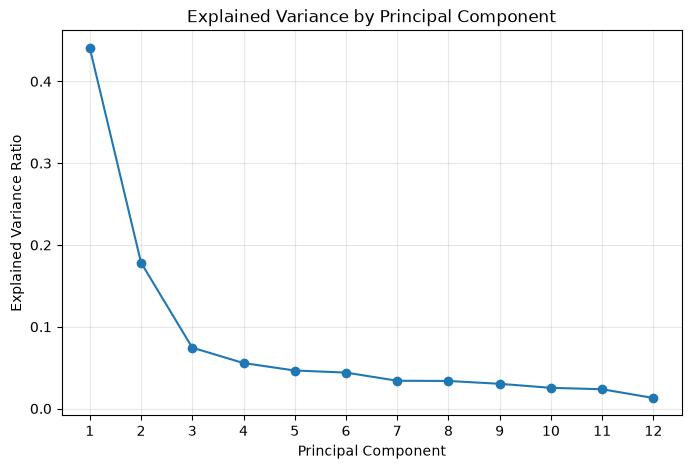

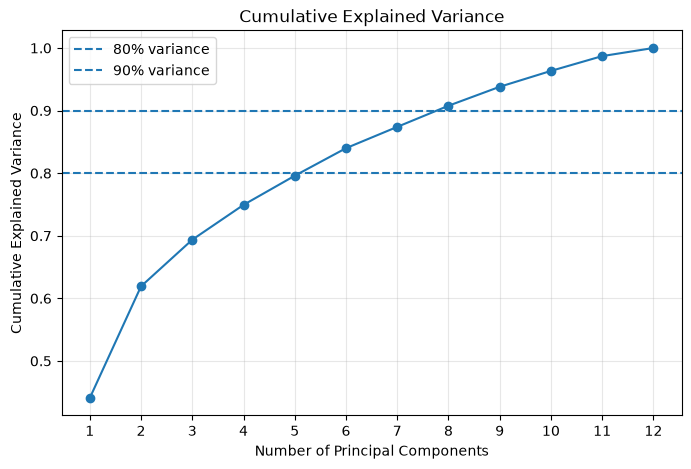

In [5]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(explained_variance) + 1),
    explained_variance,
    marker="o"
)

plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("Explained Variance by Principal Component")
plt.xticks(range(1, len(explained_variance) + 1))
plt.grid(alpha=0.3)

plt.show()

cumulative_variance = np.cumsum(explained_variance)

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)

plt.axhline(
    y=0.80,
    linestyle="--",
    label="80% variance"
)

plt.axhline(
    y=0.90,
    linestyle="--",
    label="90% variance"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Cumulative Explained Variance")
plt.xticks(range(1, len(cumulative_variance) + 1))
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [6]:
pca_6 = PCA(n_components=6)

X_pca_6 = pca_6.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    X_pca_6,
    columns=[f"PC{i}" for i in range(1, 7)],
    index=df.index
)

pca_df.head()

,PC1,PC2,PC3,PC4,PC5,PC6
0,-2.584474,-1.405557,0.501716,-0.734256,-0.053480,0.827908
1,-1.730177,2.069721,-0.643950,0.816228,-1.064037,0.376115
2,-1.233990,0.597653,-0.170696,0.586941,-0.172576,0.295104
3,-1.211256,1.277548,0.219000,0.752943,0.652578,-0.976701
4,2.985212,-1.579532,-0.033884,-0.560353,0.013543,0.107138


In [7]:
loadings = pd.DataFrame(
    pca_6.components_.T,
    columns=[f"PC{i}" for i in range(1, 7)],
    index=pca_features
)

loadings.round(3)

,PC1,PC2,PC3,PC4,PC5,PC6
Age,0.305,-0.313,0.044,0.021,-0.100,0.338
Annual_Income_000,0.306,0.226,0.161,-0.305,0.137,-0.308
Annual_Spend_000,0.321,0.284,0.160,-0.156,0.014,0.108
Store_Visits_Year,0.290,-0.138,-0.189,0.502,0.686,-0.082
Online_Orders_Year,-0.105,0.539,0.060,0.159,0.215,0.566
Complaints_Year,-0.166,-0.135,0.905,0.312,0.099,-0.132
Loyalty_Points,0.375,0.068,0.167,-0.048,-0.107,0.312
Satisfaction_Score,0.269,0.223,-0.059,0.592,-0.633,-0.215
Online_Purchase_Pct,-0.231,0.482,0.002,0.133,0.028,0.093
Promo_Purchase_Pct,-0.340,-0.161,0.115,-0.164,-0.140,0.234


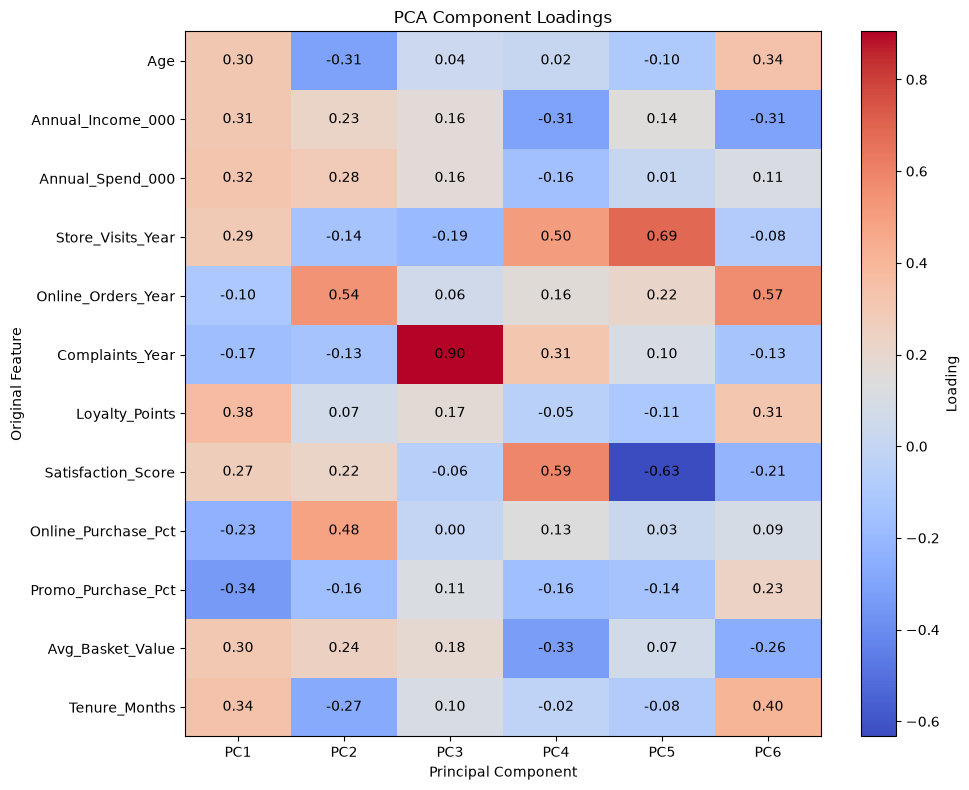

In [8]:
plt.figure(figsize=(10, 8))

plt.imshow(loadings, cmap="coolwarm", aspect="auto")

plt.colorbar(label="Loading")

plt.xticks(
    range(len(loadings.columns)),
    loadings.columns
)

plt.yticks(
    range(len(loadings.index)),
    loadings.index
)

for i in range(loadings.shape[0]):
    for j in range(loadings.shape[1]):
        plt.text(
            j,
            i,
            f"{loadings.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.title("PCA Component Loadings")
plt.xlabel("Principal Component")
plt.ylabel("Original Feature")
plt.tight_layout()
plt.show()

In [9]:
pca_output = pd.concat(
    [
        df[["Customer_ID"]],
        pca_df
    ],
    axis=1
)

pca_output.to_excel(
    "../data/OmniRetail_PCA.xlsx",
    index=False
)

print("Exported shape:", pca_output.shape)

Exported shape: (5200, 7)
